# 04. Visualizaciones — del análisis a la decisión

**Objetivo:** presentar los resultados de CoinRush mediante gráficos claros y apoyar una recomendación sobre el presupuesto de adquisición.



In [38]:
# Pandas permite leer los CSV y preparar los datos.
import pandas as pd

# Matplotlib permite crear, personalizar y guardar las figuras.
import matplotlib.pyplot as plt

# Seaborn facilita la creación de gráficos estadísticos.
import seaborn as sns

# Path permite construir las rutas de los archivos.
from pathlib import Path

# Aplicamos un estilo común a todos los gráficos.
sns.set_theme(style='whitegrid', context='notebook')

In [39]:
# Localizamos la raíz del proyecto desde notebooks o desde la propia raíz.
carpeta_actual = Path.cwd()
raiz_proyecto = (
    carpeta_actual.parent
    if carpeta_actual.name == 'notebooks'
    else carpeta_actual
)

# Localizamos los CSV que exportamos después de la limpieza.
ruta_datos = raiz_proyecto / 'data' / 'processed'

# Leemos las tablas necesarias para los gráficos por canal.
# parse_dates convierte las columnas indicadas a tipo fecha.
usuarios = pd.read_csv(
    ruta_datos / 'usuarios_limpio.csv',
    parse_dates=['fecha_instalacion']
)

sesiones = pd.read_csv(
    ruta_datos / 'sesiones_limpio.csv',
    parse_dates=['fecha']
)

compras = pd.read_csv(
    ruta_datos / 'compras_limpio.csv',
    parse_dates=['fecha']
)

ingresos_ads = pd.read_csv(
    ruta_datos / 'ingresos_ads_limpio.csv',
    parse_dates=['fecha']
)

gasto_ua = pd.read_csv(
    ruta_datos / 'gasto_ua_limpio.csv',
    parse_dates=['fecha']
)

# Comprobamos que se han leído los archivos.
print("Usuarios:", len(usuarios))
print("Sesiones:", len(sesiones))
print("Compras:", len(compras))
print("Ingresos publicitarios:", len(ingresos_ads))
print("Gasto de adquisición:", len(gasto_ua))

Usuarios: 8000
Sesiones: 44573
Compras: 4479
Ingresos publicitarios: 19999
Gasto de adquisición: 280


## 1. Retención por canal — del primer día al día 30

Comparamos la retención de CoinRush, Meta y Apple Search en D1, D7 y D30.
Cada porcentaje utiliza únicamente jugadores que pudieron alcanzar
ese plazo al corte del 22/07/2024.

Las líneas conectan tres puntos de observación; cada punto puede
corresponder a una cohorte elegible diferente.

In [40]:
# Definimos la fecha de extracción y los canales que vamos a comparar.
fecha_corte = pd.Timestamp('2024-07-22')
canales = [
    'coinrush', 'meta', 'google',
    'apple_search', 'tiktok', 'organico'
]
# Conservamos los usuarios de esos canales y las columnas necesarias.
usuarios_grafico = usuarios.loc[
    usuarios['canal_adquisicion'].isin(canales),
    ['user_id', 'canal_adquisicion', 'fecha_instalacion']
]

# Una persona cuenta una vez por fecha, aunque tenga varias sesiones.
actividad_diaria = sesiones[['user_id', 'fecha']].drop_duplicates()

# Relacionamos cada día de actividad con la instalación del jugador.
actividad = actividad_diaria.merge(
    usuarios_grafico,
    on='user_id',
    how='inner',
    validate='many_to_one'
)

# Calculamos cuántos días pasaron desde la instalación hasta cada sesión.
actividad['dia_desde_instalacion'] = (
    actividad['fecha'] - actividad['fecha_instalacion']
).dt.days

# Guardaremos un resultado por plazo y canal.
resultados = []

for dia in [1, 7, 30]:
    # Seleccionamos a quienes ya pudieron alcanzar el plazo evaluado.
    elegibles = usuarios_grafico.loc[
        (fecha_corte - usuarios_grafico['fecha_instalacion']).dt.days >= dia
    ]

    # Contamos los jugadores elegibles por canal: el denominador.
    cohortes = elegibles.groupby('canal_adquisicion')['user_id'].nunique()

    # Buscamos actividad exactamente en ese día y solo de usuarios elegibles.
    retenidos = (
        actividad.loc[
            (actividad['dia_desde_instalacion'] == dia)
            & actividad['user_id'].isin(elegibles['user_id'])
        ]
        .groupby('canal_adquisicion')['user_id']
        .nunique()
    )

    # Alineamos ambos recuentos por canal.
    resumen = cohortes.rename('cohorte').to_frame()

    # Un canal sin retenidos debe tener cero, no un dato ausente.
    resumen['retenidos'] = retenidos.reindex(
        resumen.index, fill_value=0
    )

    resumen['retencion_pct'] = (
        100 * resumen['retenidos'] / resumen['cohorte']
    ).round(1)

    resumen['dia'] = dia
    resultados.append(resumen.reset_index())

# Unimos los tres plazos en una tabla.
retencion_grafico = pd.concat(resultados, ignore_index=True)

# Revisamos los porcentajes antes de dibujar.
retencion_grafico.pivot(
    index='dia',
    columns='canal_adquisicion',
    values='retencion_pct'
)

canal_adquisicion,apple_search,coinrush,google,meta,organico,tiktok
dia,,,,,,
1,47.2,37.0,41.7,43.4,42.3,38.3
7,25.4,2.4,18.7,22.5,18.7,19.5
30,13.1,0.8,8.0,9.8,7.0,4.5


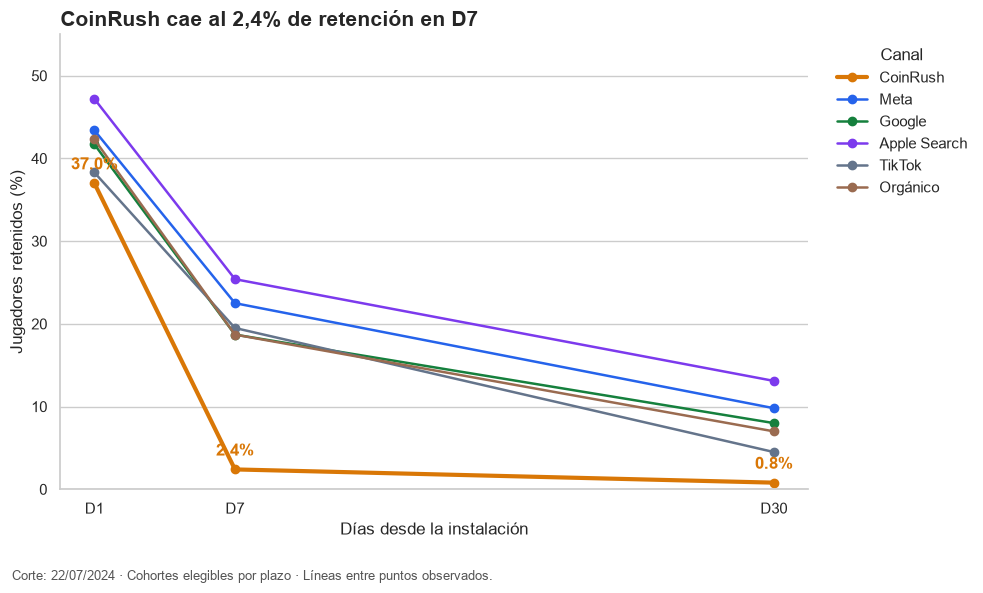

In [41]:
# Definimos el orden de los canales y sus nombres para la leyenda.
nombres = {
    'coinrush': 'CoinRush',
    'meta': 'Meta',
    'google': 'Google',
    'apple_search': 'Apple Search',
    'tiktok': 'TikTok',
    'organico': 'Orgánico'
}

# Destacamos CoinRush en naranja y asignamos colores al resto.
colores = {
    'coinrush': '#D97706',
    'meta': '#2563EB',
    'google': '#15803D',
    'apple_search': '#7C3AED',
    'tiktok': '#64748B',
    'organico': '#9A6B50'
}

# Creamos la figura y el área donde dibujaremos.
fig, ax = plt.subplots(figsize=(10, 6))

for canal, nombre in nombres.items():
    # Seleccionamos los datos del canal y ordenamos los plazos.
    datos = retencion_grafico.loc[
        retencion_grafico['canal_adquisicion'] == canal
    ].sort_values('dia')

    # Dibujamos una línea por canal con un punto en D1, D7 y D30.
    ax.plot(
        datos['dia'],
        datos['retencion_pct'],
        marker='o',
        linewidth=3 if canal == 'coinrush' else 1.8,
        color=colores[canal],
        label=nombre
    )

    # Etiquetamos CoinRush para destacar su evolución sin saturar el gráfico.
    if canal == 'coinrush':
        for dia, porcentaje in zip(datos['dia'], datos['retencion_pct']):
            ax.annotate(
                f'{porcentaje:.1f}%',
                xy=(dia, porcentaje),
                xytext=(0, 10),
                textcoords='offset points',
                ha='center',
                color=colores[canal],
                fontweight='bold'
            )

# Añadimos un título que comunica el hallazgo.
ax.set_title(
    'CoinRush cae al 2,4% de retención en D7',
    loc='left',
    fontsize=15,
    fontweight='bold'
)

# Etiquetamos los ejes y los tres plazos observados.
ax.set_xlabel('Días desde la instalación')
ax.set_ylabel('Jugadores retenidos (%)')
ax.set_xticks([1, 7, 30], labels=['D1', 'D7', 'D30'])
ax.set_ylim(0, 55)

# Simplificamos la cuadrícula y colocamos la leyenda fuera de las líneas.
ax.grid(axis='x', visible=False)
ax.legend(title='Canal', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine(ax=ax)

# Aclaramos que cada plazo tiene su propia cohorte elegible.
fig.text(
    0.02, 0.02,
    'Corte: 22/07/2024 · Cohortes elegibles por plazo · Líneas entre puntos observados.',
    fontsize=9,
    color='#555555'
)

# Ajustamos los márgenes para dejar espacio a la nota.
fig.tight_layout(rect=[0, 0.06, 1, 1])

# Guardamos el gráfico para utilizarlo después en el informe y el README.
ruta_imagenes = raiz_proyecto / 'docs' / 'img'
ruta_imagenes.mkdir(parents=True, exist_ok=True)

fig.savefig(
    ruta_imagenes / 'retencion_por_canal.png',
    dpi=200,
    bbox_inches='tight'
)

# Mostramos la figura dentro del notebook.
plt.show()

## 2. Conversión a pagador por canal

Comparamos el porcentaje de jugadores de cada canal que realizó al menos una compra válida durante el periodo observado.
Conversión = pagadores únicos / jugadores del canal × 100.

In [42]:
# Contamos jugadores unicos por canal
jugadores_canal = (
    usuarios.groupby('canal_adquisicion')['user_id']
    .nunique()
    .rename('jugadores')
)

# Creamos pagadores unicos
pagadores = compras[['user_id']].drop_duplicates()

# Añadimos el canal de cada comprados desde usuarios
pagadores_con_canal = pagadores.merge(
    usuarios[['user_id','canal_adquisicion']],
    on = 'user_id',
    how='left',
    validate='one_to_one'
)

# COntamos pagadores unicos por canal.
pagadores_canal = (
    pagadores_con_canal.groupby('canal_adquisicion')['user_id']
    .nunique()
    .rename('pagadores')
)

# Reunimos ambos recuentos conservando los canales
conversion_grafico = jugadores_canal.to_frame().join(pagadores_canal)

# Si un canal no tiene compradores, su recuento es 0.
conversion_grafico['pagadores'] = (
    conversion_grafico['pagadores'].fillna(0).astype(int)
    )

# Calculamos la conversion como %.
conversion_grafico['conversion_pct'] = (
    100 *
    conversion_grafico['pagadores'] 
    / conversion_grafico['jugadores']
).round(2)

# Convertimos el canal en una columna y ordenamos de mayor a menor.
conversion_grafico = (
    conversion_grafico.reset_index()
    .sort_values('conversion_pct', ascending=False)
)

conversion_grafico

,canal_adquisicion,jugadores,pagadores,conversion_pct
0,apple_search,900,23,2.56
3,meta,1600,37,2.31
4,organico,600,12,2.00
2,google,1400,25,1.79
5,tiktok,700,7,1.00
1,coinrush,2800,3,0.11


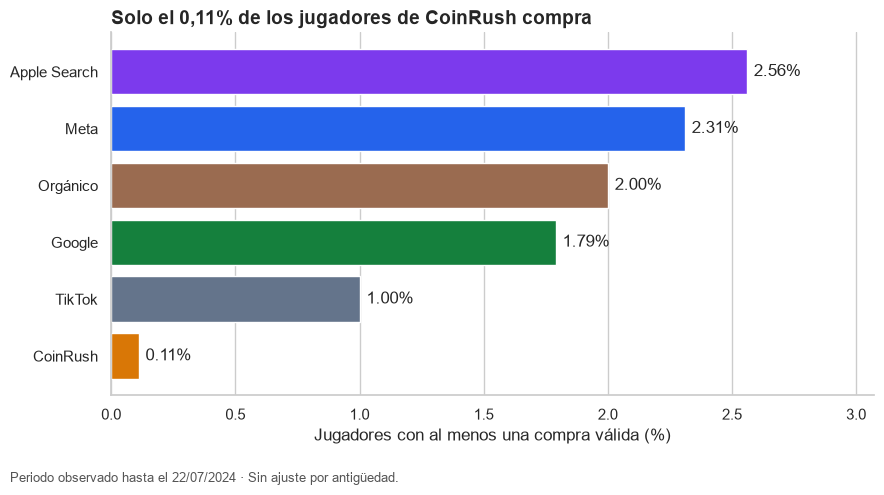

In [43]:
# Utilizamos los mismos nombres y colores que en el gráfico de retención.
etiquetas = conversion_grafico['canal_adquisicion'].map(nombres)
colores_barras = conversion_grafico['canal_adquisicion'].map(colores)

fig, ax = plt.subplots(figsize=(9, 5))

# Dibujamos una barra horizontal por canal.
barras = ax.barh(
    etiquetas,
    conversion_grafico['conversion_pct'],
    color=colores_barras
)

# Colocamos el canal con mayor conversión arriba.
ax.invert_yaxis()

# Escribimos el porcentaje al final de cada barra.
ax.bar_label(
    barras,
    labels=[
        f'{valor:.2f}%'
        for valor in conversion_grafico['conversion_pct']
    ],
    padding=5
)

ax.set_title(
    'Solo el 0,11% de los jugadores de CoinRush compra',
    loc='left',
    fontsize=14,
    fontweight='bold'
)
ax.set_xlabel('Jugadores con al menos una compra válida (%)')
ax.set_ylabel('')

# Dejamos espacio para las etiquetas y eliminamos líneas innecesarias.
ax.set_xlim(0, conversion_grafico['conversion_pct'].max() * 1.2)
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)
sns.despine(ax=ax)

fig.text(
    0.02, 0.02,
    'Periodo observado hasta el 22/07/2024 · Sin ajuste por antigüedad.',
    fontsize=9,
    color='#555555'
)
fig.tight_layout(rect=[0, 0.06, 1, 1])

# Guardamos la imagen; actualiza el archivo si ya existe.
ruta_imagenes = raiz_proyecto / 'docs' / 'img'
ruta_imagenes.mkdir(parents=True, exist_ok=True)

fig.savefig(
    ruta_imagenes / 'conversion_por_canal.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## 3. ROAS por canal — recuperación del gasto de adquisición

Comparamos el ingreso neto registrado con el gasto publicitario
de cada canal: ROAS = (compras × 0.70 + anuncios) / gasto.

La línea en 1 señala la recuperación del gasto de adquisición.
Por debajo, el ingreso todavía no lo cubre; por encima, lo supera,
antes de descontar otros costes.

Excluimos el orgánico porque su gasto registrado es cero.


In [44]:
# Asociamos cada compra con el canal del usuario.
compras_canal = compras.merge(
    usuarios[['user_id','canal_adquisicion']],
    on = 'user_id',
    how = 'left',
    validate = 'many_to_one'
)
# Sumamos compras por canal y descontamos el 30% de la comision
iap_neto = (
    compras_canal.groupby('canal_adquisicion')['importe'].sum() * 0.70
).rename('iap_neto')

# Asociamos cada anuncio con el canal del usuario
anuncios_canal = ingresos_ads.merge(
    usuarios[['user_id','canal_adquisicion']],
    on = 'user_id',
    how = 'left',
    validate = 'many_to_one'
)

# Sumamos el ingreso publicitario 
# min_count=1 conserva NaN si todos los ingresos de un canal son desconocidos.
ingreso_anuncios = (
    anuncios_canal.groupby('canal_adquisicion')['ingreso']
    .sum(min_count=1)
    .rename('ingreso_anuncios')
)

# Sumamos el gasto publicitario por canal.
# Renombramos el índice para que se llame igual que en las otras tablas.
gasto_canal = (
    gasto_ua.groupby('canal')['gasto']
    .sum()
    .rename('gasto')
    .rename_axis('canal_adquisicion')
)

# Reunimos los importes usando el canal como índice.
roas_grafico = gasto_canal.to_frame().join([iap_neto, ingreso_anuncios])
# Si un canal no tiene compras, su ingreso por compras es cero.
roas_grafico['iap_neto'] = roas_grafico['iap_neto'].fillna(0)

# Calculamos el ingreso neto registrado.
roas_grafico['ingreso_neto'] = (
    roas_grafico['iap_neto'] + roas_grafico['ingreso_anuncios']
)
# Conservamos únicamente canales con gasto positivo.
roas_grafico = roas_grafico.loc[roas_grafico['gasto'] > 0].copy()

# Calculamos el ROAS sin redondear los importes previamente.
roas_grafico['roas'] = (
    roas_grafico['ingreso_neto'] / roas_grafico['gasto']
)

# Convertimos el canal en columna y ordenamos de menor a mayor ROAS.
roas_grafico = (
    roas_grafico.reset_index()
    .sort_values('roas')
)

# Mostramos dos decimales para contrastar con SQL.
roas_grafico.round(2)

,canal_adquisicion,gasto,iap_neto,ingreso_anuncios,ingreso_neto,roas
1,coinrush,1259.99,52.31,286.0,338.31,0.27
4,tiktok,839.98,488.52,402.0,890.52,1.06
2,google,2100.01,1551.69,880.0,2431.69,1.16
3,meta,2880.01,2649.50,1240.0,3889.50,1.35
0,apple_search,1980.02,2123.97,690.0,2813.97,1.42


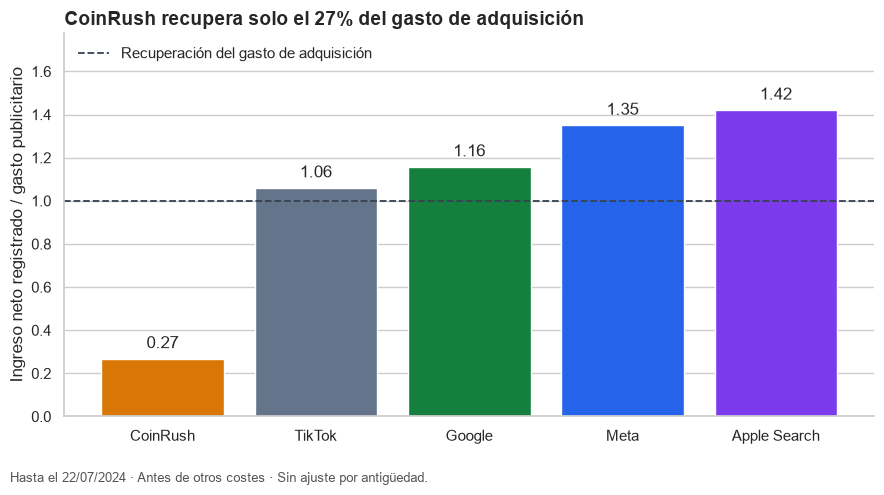

In [45]:
# Reutilizamos los nombres y colores de los gráficos anteriores.
etiquetas = roas_grafico['canal_adquisicion'].map(nombres)
colores_barras = roas_grafico['canal_adquisicion'].map(colores)

fig, ax = plt.subplots(figsize=(9, 5))

# Dibujamos una barra por canal de pago.
barras = ax.bar(
    etiquetas,
    roas_grafico['roas'],
    color=colores_barras
)

# Añadimos el ROAS sobre cada barra.
ax.bar_label(
    barras,
    labels=[f'{valor:.2f}' for valor in roas_grafico['roas']],
    padding=5
)

# Una línea horizontal en 1 marca la recuperación del gasto publicitario.
ax.axhline(
    y=1,
    color='#374151',
    linestyle='--',
    linewidth=1.3,
    label='Recuperación del gasto de adquisición'
)

ax.set_title(
    'CoinRush recupera solo el 27% del gasto de adquisición',
    loc='left',
    fontsize=14,
    fontweight='bold'
)
ax.set_xlabel('')
ax.set_ylabel('Ingreso neto registrado / gasto publicitario')
ax.set_ylim(0, roas_grafico['roas'].max() * 1.25)

# Simplificamos el gráfico y mantenemos la cuadrícula detrás de las barras.
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left')
sns.despine(ax=ax)

fig.text(
    0.02, 0.02,
    'Hasta el 22/07/2024 · Antes de otros costes · Sin ajuste por antigüedad.',
    fontsize=9,
    color='#555555'
)
fig.tight_layout(rect=[0, 0.06, 1, 1])

# Guardamos la figura para el informe y el README.
ruta_imagenes = raiz_proyecto / 'docs' / 'img'
ruta_imagenes.mkdir(parents=True, exist_ok=True)

fig.savefig(
    ruta_imagenes / 'roas_por_canal.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## 4. La cifra clave para la decisión

**Objetivo:** traducir el ROAS de CoinRush a euros recuperados por cada
1.000 € invertidos, para comunicar de forma sencilla cuánto gasto
de adquisición se ha recuperado hasta la extracción.

In [46]:
# Recuperamos los importes de CoinRush de la tabla que ya calculamos.
coinrush = roas_grafico.loc[
    roas_grafico['canal_adquisicion'] == 'coinrush'
].iloc[0]

# Contamos sus jugadores únicos.
instalaciones_coinrush = usuarios.loc[
    usuarios['canal_adquisicion'] == 'coinrush',
    'user_id'
].nunique()

# Calculamos con los importes originales, sin redondear previamente.
ltv_coinrush = coinrush['ingreso_neto'] / instalaciones_coinrush
cpi_coinrush = coinrush['gasto'] / instalaciones_coinrush
roas_coinrush = coinrush['ingreso_neto'] / coinrush['gasto']

# Traducimos el retorno a euros por cada 1.000 € invertidos.
euros_recuperados = 1000 * roas_coinrush

# Redondeamos a decenas para comunicar una cifra aproximada y memorable.
cifra_grande = round(euros_recuperados, -1)

print(f"LTV neto observado de CoinRush: {ltv_coinrush:.2f} EUR")
print(f"CPI de CoinRush: {cpi_coinrush:.2f} EUR")
print(f"ROAS de CoinRush: {roas_coinrush:.2f}")
print(
    f"CIFRA GRANDE: por cada 1.000 EUR invertidos en CoinRush, "
    f"hemos registrado aproximadamente {cifra_grande:.0f} EUR netos "
    f"hasta la extracción."
)

LTV neto observado de CoinRush: 0.12 EUR
CPI de CoinRush: 0.45 EUR
ROAS de CoinRush: 0.27
CIFRA GRANDE: por cada 1.000 EUR invertidos en CoinRush, hemos registrado aproximadamente 270 EUR netos hasta la extracción.


## 4. La cifra clave de CoinRush

Por cada **1.000 € invertidos en CoinRush**, se han registrado
aproximadamente **270 € netos hasta la extracción**.

Su ingreso neto observado por jugador es de **0,12 €**, frente
a un CPI de **0,45 €**: un ROAS de **0,27**.

La captación barata no ha compensado el bajo ingreso generado.
La cifra es acumulada, no una previsión del retorno final.